# EDA — Puntos de calor NASA FIRMS (MODIS + VIIRS)
**NASA Space Apps 2026 · Costa Rica** · Reto *Harmonization of MODIS and VIIRS Hot Spots*

Este notebook lee los ZIP de `data/raw` **directamente, sin descomprimirlos ni consolidarlos**, y solo los países que elijas, así que es rápido.
Si ya corriste `scripts/consolidar.py`, puedes leer el Parquet en su lugar (ver sección 1b).

In [1]:
import io, re, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (11, 4)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CONSOLIDADO = ROOT / "data" / "consolidado"

SENSORS = {
    "modis": "MODIS",
    "viirs-snpp": "VIIRS_SNPP",
    "viirs-jpss1": "VIIRS_NOAA20",
    "viirs-jpss2": "VIIRS_NOAA21",
}
RENAME = {
    "brightness": "bright_mir",
    "bright_ti4": "bright_mir",
    "bright_t31": "bright_tir",
    "bright_ti5": "bright_tir",
}

## 0 · Inventario de archivos

In [2]:
inv = []
for p in sorted(RAW.glob("*_all_countries.zip")):
    prefix, year = re.match(r"(.+?)_(\d{4})_all_countries\.zip", p.name).groups()
    inv.append(
        {
            "sensor": SENSORS.get(prefix, prefix),
            "year": int(year),
            "MB": round(p.stat().st_size / 1e6, 1),
        }
    )
inv = pd.DataFrame(inv)
print(f"{len(inv)} ZIP · {inv.MB.sum() / 1000:.1f} GB")
inv.pivot_table(index="year", columns="sensor", values="MB", aggfunc="sum")

40 ZIP · 6.9 GB


sensor,MODIS,VIIRS_NOAA20,VIIRS_SNPP
year,,,
2000,4.7,NaN,NaN
2001,31.5,NaN,NaN
2002,65.3,NaN,NaN
2003,90.4,NaN,NaN
2004,89.4,NaN,NaN
2005,89.9,NaN,NaN
2006,82.4,NaN,NaN
2007,90.0,NaN,NaN
2008,84.6,NaN,NaN


## 1 · Cargar países desde los ZIP
Cambia `PAISES` (nombres como en FIRMS: `Costa_Rica`, `Nicaragua`, `Panama`…).

In [3]:
PAISES = ["Costa_Rica"]  # p. ej. ["Costa_Rica", "Nicaragua", "Panama", "Honduras"]


def leer_paises(paises, raw=RAW):
    frames = []
    for p in sorted(raw.glob("*_all_countries.zip")):
        prefix, year = re.match(r"(.+?)_(\d{4})_all_countries\.zip", p.name).groups()
        with zipfile.ZipFile(p) as zf:
            for name in zf.namelist():
                for pais in paises:
                    if name.endswith(f"_{year}_{pais}.csv"):
                        df = pd.read_csv(
                            zf.open(name),
                            dtype={"confidence": str, "satellite": str, "version": str},
                        )
                        df = df.rename(columns=RENAME)
                        df["sensor"] = SENSORS.get(prefix, prefix)
                        df["country"] = pais.replace("_", " ")
                        frames.append(df)
    df = pd.concat(frames, ignore_index=True)
    df["acq_date"] = pd.to_datetime(df["acq_date"])
    df["year"] = df.acq_date.dt.year
    df["month"] = df.acq_date.dt.month
    return df


df = leer_paises(PAISES)
print(f"{len(df):,} detecciones")
df.head()

102,931 detecciones


,latitude,longitude,bright_mir,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_tir,frp,daynight,type,sensor,country,year,month
0,10.4644,-84.7059,307.0,1.4,1.2,2000-11-08,1643,Terra,MODIS,34,6.2,290.6,7.1,D,1,MODIS,Costa Rica,2000,11
1,10.4648,-84.7029,314.2,1.0,1.0,2000-11-10,415,Terra,MODIS,89,6.2,287.1,13.1,N,1,MODIS,Costa Rica,2000,11
2,10.4651,-84.6987,316.4,1.0,1.0,2000-11-10,1631,Terra,MODIS,67,6.2,288.8,11.6,D,1,MODIS,Costa Rica,2000,11
3,10.4148,-85.5350,321.3,1.0,1.0,2000-11-26,1630,Terra,MODIS,54,6.2,303.7,11.0,D,0,MODIS,Costa Rica,2000,11
4,10.4528,-85.2199,312.0,2.2,1.4,2000-12-08,1654,Terra,MODIS,46,6.2,295.8,12.5,D,0,MODIS,Costa Rica,2000,12


### 1b · (Opcional) leer el Parquet consolidado

In [4]:
# df = pd.read_parquet(CONSOLIDADO, filters=[("country", "in", [p.replace("_", " ") for p in PAISES])])
# df["acq_date"] = pd.to_datetime(df["acq_date"]); df["year"] = df.acq_date.dt.year; df["month"] = df.acq_date.dt.month

## 2 · Estructura y calidad

In [5]:
df.info()
df.isna().mean().round(3).to_frame("fraccion_nula").T

<class 'pandas.DataFrame'>
RangeIndex: 102931 entries, 0 to 102930
Data columns (total 19 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   latitude    102931 non-null  float64       
 1   longitude   102931 non-null  float64       
 2   bright_mir  102931 non-null  float64       
 3   scan        102931 non-null  float64       
 4   track       102931 non-null  float64       
 5   acq_date    102931 non-null  datetime64[us]
 6   acq_time    102931 non-null  int64         
 7   satellite   102931 non-null  str           
 8   instrument  102931 non-null  str           
 9   confidence  102931 non-null  str           
 10  version     102931 non-null  str           
 11  bright_tir  102931 non-null  float64       
 12  frp         102931 non-null  float64       
 13  daynight    102931 non-null  str           
 14  type        102931 non-null  int64         
 15  sensor      102931 non-null  str           
 16  country     1

,latitude,longitude,bright_mir,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_tir,frp,daynight,type,sensor,country,year,month
fraccion_nula,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
print("Satélites por sensor:")
display(df.groupby(["sensor", "satellite"]).size().unstack(fill_value=0))
print("Tipo de fuente (0=vegetación, 1=volcán, 2=estática/industria, 3=costa afuera):")
display(df.groupby(["sensor", "type"]).size().unstack(fill_value=0))
print("Día / noche:")
display(df.groupby(["sensor", "daynight"]).size().unstack(fill_value=0))

Satélites por sensor:


satellite,Aqua,N,N20,Terra
sensor,,,,
MODIS,15344,0,0,13017
VIIRS_NOAA20,0,0,34766,0
VIIRS_SNPP,0,39804,0,0


Tipo de fuente (0=vegetación, 1=volcán, 2=estática/industria, 3=costa afuera):


type,0,1,2,3
sensor,,,,
MODIS,27293,415,501,152
VIIRS_NOAA20,34451,108,174,33
VIIRS_SNPP,39268,465,34,37


Día / noche:


daynight,D,N
sensor,,
MODIS,22598,5763
VIIRS_NOAA20,25850,8916
VIIRS_SNPP,29002,10802


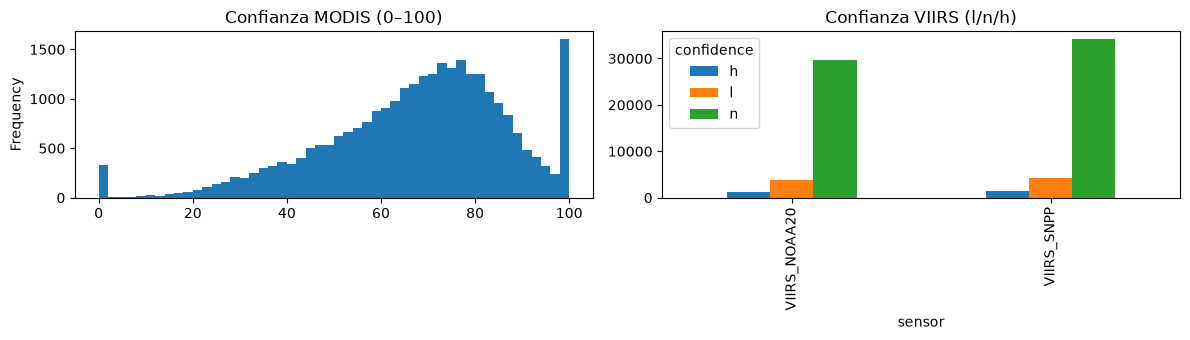

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
pd.to_numeric(df.loc[df.sensor == "MODIS", "confidence"]).plot.hist(
    bins=50, ax=ax[0], title="Confianza MODIS (0–100)"
)
df.loc[df.sensor != "MODIS"].groupby(
    ["sensor", "confidence"]
).size().unstack().plot.bar(ax=ax[1], title="Confianza VIIRS (l/n/h)")
plt.tight_layout()

## 3 · Detecciones por año y sensor
Aquí se ve el problema del reto: cada sensor cuenta distinto.

sensor,MODIS,VIIRS_NOAA20,VIIRS_SNPP
year,,,
2000,55.0,NaN,NaN
2001,832.0,NaN,NaN
2002,733.0,NaN,NaN
2003,1650.0,NaN,NaN
2004,1496.0,NaN,NaN
2005,1076.0,NaN,NaN
2006,948.0,NaN,NaN
2007,1135.0,NaN,NaN
2008,826.0,NaN,NaN


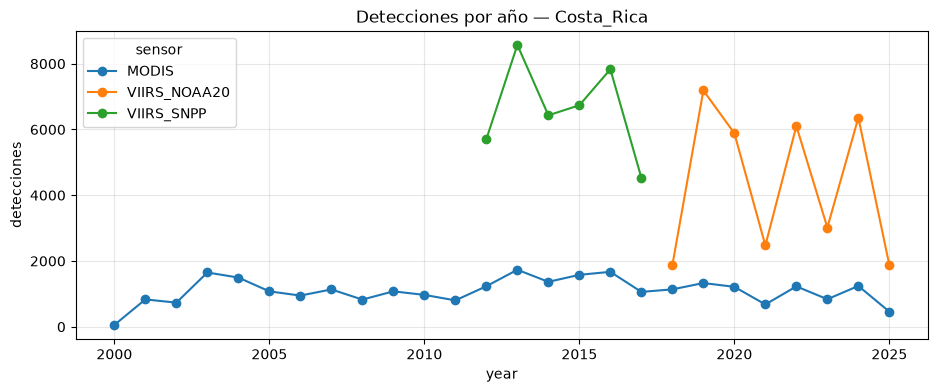

In [8]:
anual = df.groupby(["year", "sensor"]).size().unstack()
anual.plot(marker="o", title=f"Detecciones por año — {', '.join(PAISES)}")
plt.ylabel("detecciones")
plt.grid(alpha=0.3)
anual

sensor,VIIRS_NOAA20,VIIRS_SNPP
year,,
2012,NaN,4.63
2013,NaN,4.95
2014,NaN,4.71
2015,NaN,4.27
2016,NaN,4.69
2017,NaN,4.27
2018,1.64,NaN
2019,5.41,NaN
2020,4.85,NaN


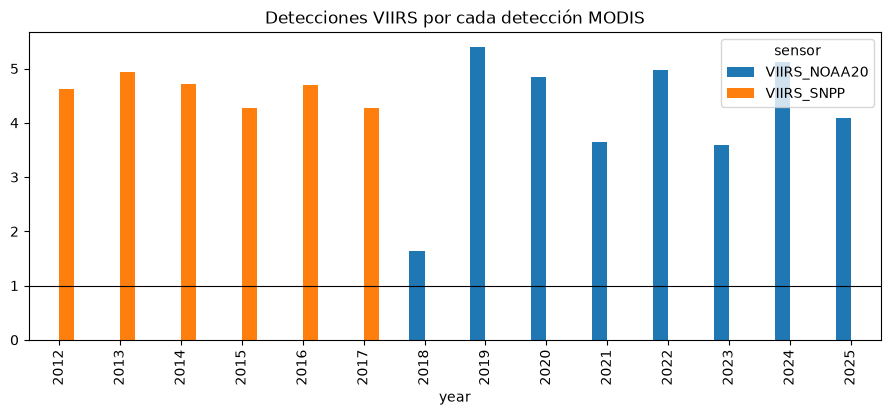

In [9]:
# Traslape: razón VIIRS / MODIS en los años donde coexisten
ratio = (anual.drop(columns="MODIS").div(anual["MODIS"], axis=0)).dropna(how="all")
ratio.plot.bar(title="Detecciones VIIRS por cada detección MODIS")
plt.axhline(1, color="k", lw=0.8)
ratio.round(2)

## 4 · Calendario de quemas (año × mes)

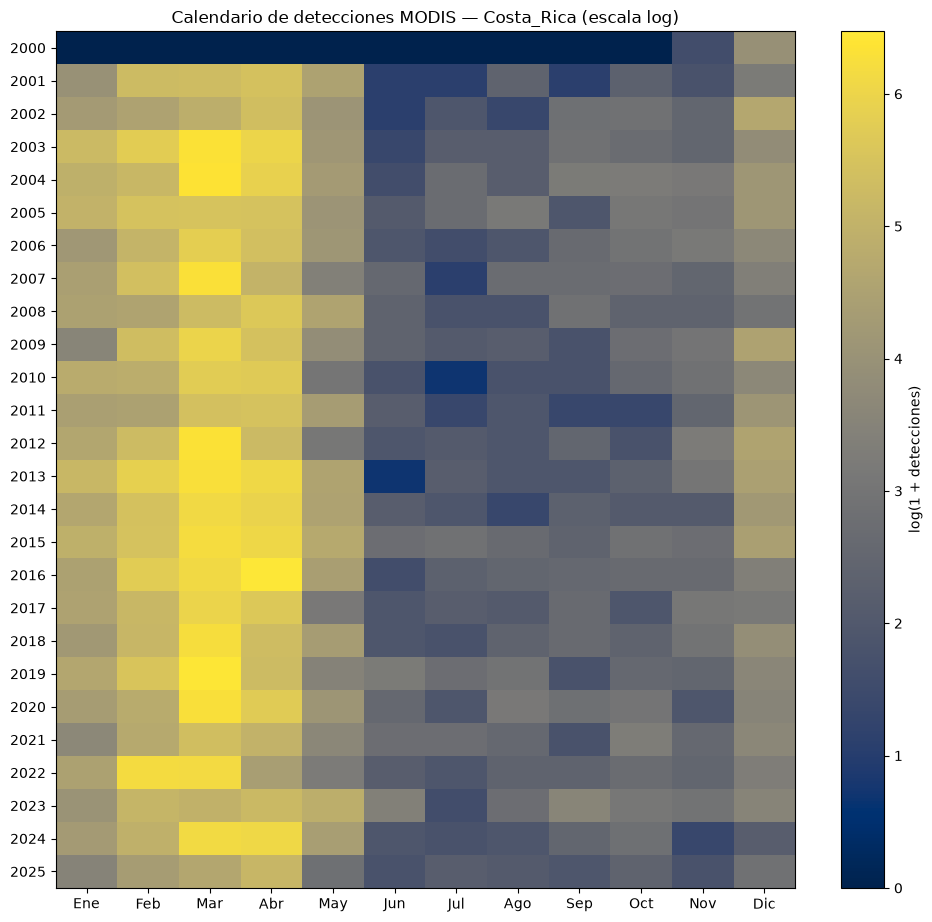

In [10]:
SENSOR = "MODIS"  # cambia a "VIIRS_NOAA20" o "VIIRS_SNPP"
cal = (
    df[df.sensor == SENSOR]
    .groupby(["year", "month"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=range(1, 13), fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 0.32 * len(cal) + 1))
im = ax.imshow(np.log1p(cal), cmap="cividis", aspect="auto")
ax.set_xticks(
    range(12),
    [
        "Ene",
        "Feb",
        "Mar",
        "Abr",
        "May",
        "Jun",
        "Jul",
        "Ago",
        "Sep",
        "Oct",
        "Nov",
        "Dic",
    ],
)
ax.set_yticks(range(len(cal)), cal.index)
ax.set_title(f"Calendario de detecciones {SENSOR} — {', '.join(PAISES)} (escala log)")
plt.colorbar(im, ax=ax, label="log(1 + detecciones)")
plt.tight_layout()

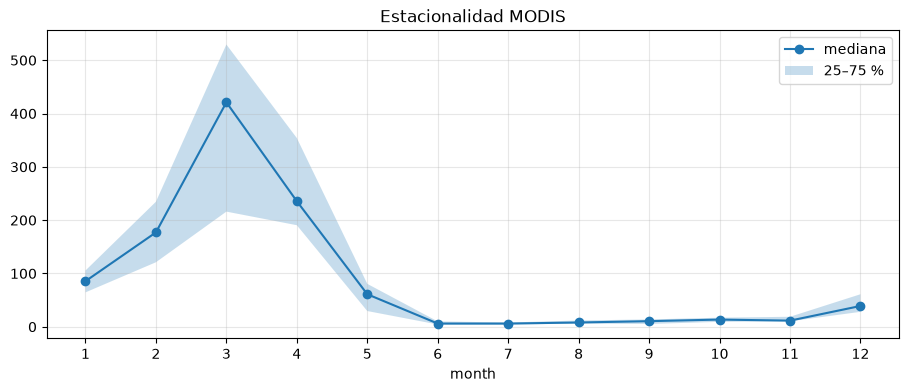

In [11]:
# Perfil estacional: mediana y rango intercuartil por mes
est = cal.describe(percentiles=[0.25, 0.5, 0.75]).T[["25%", "50%", "75%"]]
ax = est["50%"].plot(marker="o", label="mediana")
ax.fill_between(est.index, est["25%"], est["75%"], alpha=0.25, label="25–75 %")
ax.set_xticks(range(1, 13))
ax.set_title(f"Estacionalidad {SENSOR}")
ax.legend()
ax.grid(alpha=0.3)

## 5 · Intensidad (FRP) y brillo

sensor               MODIS  VIIRS_NOAA20  VIIRS_SNPP
frp        count  28361.00      34766.00    39804.00
           mean      24.95          6.66        6.78
           std       32.07         10.24        9.37
           min        2.60          0.12        0.09
           25%        9.60          2.38        2.43
           50%       15.50          4.41        4.47
           75%       27.70          7.41        7.64
           max      859.80        413.50      263.09
bright_mir count  28361.00      34766.00    39804.00
           mean     323.03        333.47      333.59
           std       12.11         15.46       15.95
           min      300.00        207.93      208.00
           25%      315.30        329.74      329.12
           50%      322.20        335.64      335.89
           75%      328.60        342.54      343.24
           max      428.70        367.00      367.00
bright_tir count  28361.00      34766.00    39804.00
           mean     299.92        299.04      298.52
           std        6.75          7.56        8.14
           min      267.00        236.05      244.22
           25%      295.20        294.13      293.41
           50%      300.30        299.03      298.67
           75%      304.70        304.39      304.20
           max      323.50        347.20      350.87
scan       count  28361.00      34766.00    39804.00
           mean       1.49          0.45        0.45
           std        0.69          0.08        0.08
           min        1.00          0.32        0.32
           25%        1.00          0.39        0.39
           50%        1.20          0.43        0.43
           75%        1.70          0.50        0.50
           max        4.80          0.80        0.80
track      count  28361.00      34766.00    39804.00
           mean       1.18          0.47        0.47
           std        0.22          0.11        0.11
           min        1.00          0.36        0.36
           25%        1.00          0.38        0.38
           50%        1.10          0.44        0.44
           75%        1.30          0.55        0.55
           max        2.00          0.78        0.78

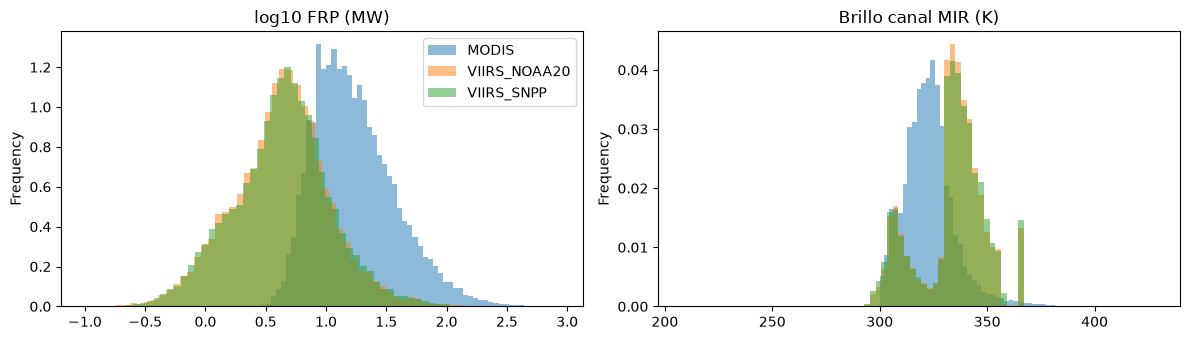

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for s, g in df.groupby("sensor"):
    np.log10(g.frp.clip(lower=0.1)).plot.hist(
        bins=60, alpha=0.5, ax=ax[0], label=s, density=True
    )
    g.bright_mir.plot.hist(bins=60, alpha=0.5, ax=ax[1], label=s, density=True)
ax[0].set_title("log10 FRP (MW)")
ax[1].set_title("Brillo canal MIR (K)")
ax[0].legend()
plt.tight_layout()
df.groupby("sensor")[
    ["frp", "bright_mir", "bright_tir", "scan", "track"]
].describe().T.round(2)

## 6 · Mapa de detecciones

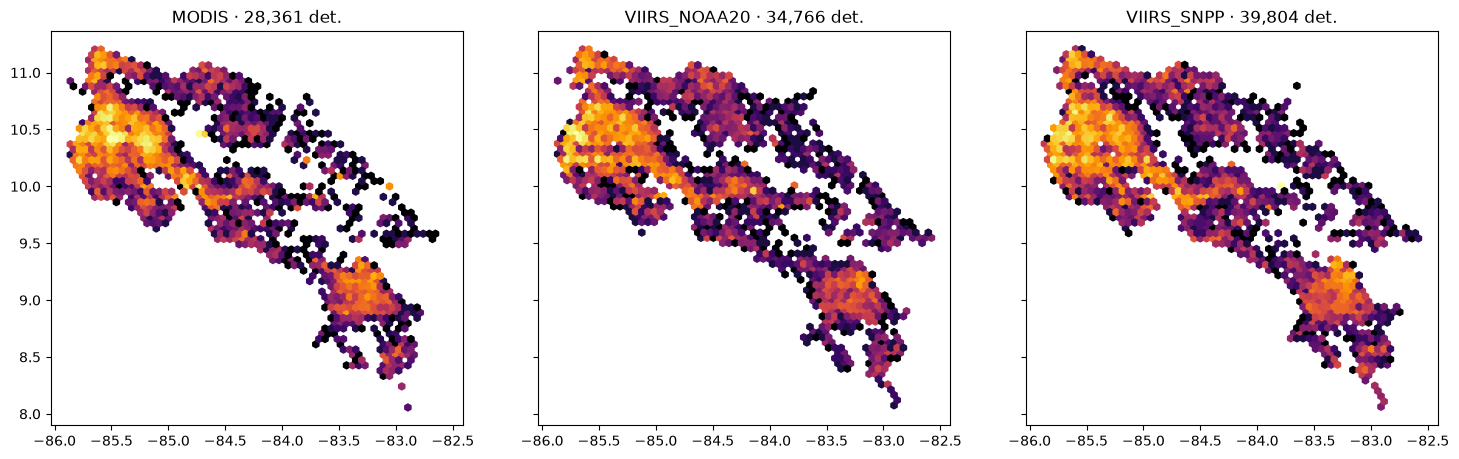

In [13]:
fig, axs = plt.subplots(
    1,
    df.sensor.nunique(),
    figsize=(5 * df.sensor.nunique(), 4.5),
    sharex=True,
    sharey=True,
)
for ax, (s, g) in zip(np.atleast_1d(axs), df.groupby("sensor")):
    ax.hexbin(
        g.longitude, g.latitude, gridsize=60, bins="log", cmap="inferno", mincnt=1
    )
    ax.set_title(f"{s} · {len(g):,} det.")
    ax.set_aspect("equal")
plt.tight_layout()

## 7 · Notas para la armonización
- Resolución: MODIS 1 km frente a VIIRS 375 m. Un incendio genera varios píxeles VIIRS.
- Traslapes: MODIS + S-NPP (2012–2017) y MODIS + NOAA-20 (2018–2025).
- Revisar `type` (fuentes estáticas) y los umbrales de `confidence` antes de comparar.
- S-NPP dejó de entregar datos el 2-nov-2026, así que NOAA-20 y NOAA-21 son la continuidad.